In [ ]:
import torch

print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    print('VRAM:', round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), 'GB')
else:
    print('WARNING: No GPU detected.')
    print('Go to Runtime → Change runtime type → Hardware accelerator → GPU (T4)')

CUDA available: True
GPU: Tesla T4
VRAM: 15.6 GB


In [ ]:
!pip install -q timm albumentations scikit-learn matplotlib seaborn tqdm
print('Dependencies installed.')

Dependencies installed.


In [ ]:
import os
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

# ============================================================
# PATH CONSTANTS — edit DRIVE_ROOT if you used a different folder
# ============================================================
DRIVE_ROOT   = '/content/drive/MyDrive/oral_cancer_detection'
DRIVE_DATA    = f'{DRIVE_ROOT}/data'
DRIVE_MODELS  = f'{DRIVE_ROOT}/models'

LOCAL_DATA_RAW   = '/content/data/raw'
LOCAL_DATA_SPLIT = '/content/data/split'
LOCAL_MODELS     = '/content/models'

BEST_MODEL_NAME  = 'efficientnet_b3_lips_v1.pth'
RESUME_CKPT_NAME = 'lips_resume_checkpoint.pth'

# Create all required local directories
for d in [LOCAL_DATA_RAW, LOCAL_DATA_SPLIT, LOCAL_MODELS,
          DRIVE_DATA, DRIVE_MODELS]:
    os.makedirs(d, exist_ok=True)

print('Google Drive mounted.')
print(f'Drive data   : {DRIVE_DATA}')
print(f'Drive models : {DRIVE_MODELS}')
print(f'Local split  : {LOCAL_DATA_SPLIT}')
print(f'Local models : {LOCAL_MODELS}')
print('All directories ready.')

Mounted at /content/drive
Google Drive mounted.
Drive data   : /content/drive/MyDrive/oral_cancer_detection/data
Drive models : /content/drive/MyDrive/oral_cancer_detection/models
Local split  : /content/data/split
Local models : /content/models
All directories ready.


In [ ]:
import os
import shutil
import zipfile
from pathlib import Path

EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp'}

def count_images(directory):
    p = Path(directory)
    if not p.exists():
        return 0
    return sum(1 for f in p.rglob('*') if f.suffix.lower() in EXTS)

# Updated path based on your specific Drive location
USER_DATA_PATH = f"{DRIVE_DATA}/kaggle_lips/Oral cancer Dataset 2.0/OC Dataset kaggle new"

print(f"Checking path: {USER_DATA_PATH}")

if os.path.isdir(USER_DATA_PATH):
    n_found = count_images(USER_DATA_PATH)
    if n_found > 0:
        print(f'Found dataset on Drive ({n_found} images) — copying locally...')
        if os.path.exists(LOCAL_DATA_RAW):
            shutil.rmtree(LOCAL_DATA_RAW)
        # We copy the parent folder or the specific folder to LOCAL_DATA_RAW
        shutil.copytree(USER_DATA_PATH, LOCAL_DATA_RAW)
        print(f'Copied {count_images(LOCAL_DATA_RAW)} images to {LOCAL_DATA_RAW}')
    else:
        print(f'Directory found, but no images detected in: {USER_DATA_PATH}')
else:
    print(f'Directory NOT found at: {USER_DATA_PATH}')
    print('Please ensure your folder names in Google Drive match exactly (case-sensitive).')

print(f'\nDataset ready: {count_images(LOCAL_DATA_RAW)} images in {LOCAL_DATA_RAW}')

Checking path: /content/drive/MyDrive/oral_cancer_detection/data/kaggle_lips/Oral cancer Dataset 2.0/OC Dataset kaggle new
Found dataset on Drive (950 images) — copying locally...
Copied 950 images to /content/data/raw

Dataset ready: 950 images in /content/data/raw


In [ ]:
import os
import re
import unicodedata
import zipfile
import shutil
from pathlib import Path
from collections import defaultdict

EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp'}

# ============================================================
# FOLDER_MAP — keyword → class.  Specific patterns first.
# ============================================================
FOLDER_MAP = {
    'non cancer':  'Normal',
    'non_cancer':  'Normal',
    'noncancer':   'Normal',
    'non-cancer':  'Normal',
    'non oral':    'Normal',
    'healthy':     'Normal',
    'benign':      'Normal',
    'normal':      'Normal',
    'cancer':      'OSCC',
    'oscc':        'OSCC',
    'malignant':   'OSCC',
}

# Negatives used by the smart heuristic fallback
_NON_CANCER_HINTS = ('non', 'healthy', 'benign', 'normal')

# ---- helpers ----

def _norm(s):
    """Lowercase, NFC unicode, collapse whitespace."""
    s = unicodedata.normalize('NFC', str(s)).lower()
    return re.sub(r'\s+', ' ', s).strip()

def _classify(folder_name, rel_parts):
    """
    Classify one leaf directory.
    Priority:
      1. FOLDER_MAP match on folder name
      2. FOLDER_MAP match on any ancestor path part
      3. Smart heuristic: 'cancer' in name → OSCC unless negatives present
    Returns class string or None.
    """
    name = _norm(folder_name)

    # 1) direct match on leaf name
    for kw, cls in FOLDER_MAP.items():
        if kw in name:
            return cls

    # 2) match on each ancestor segment
    for part in rel_parts[:-1]:
        p = _norm(part)
        for kw, cls in FOLDER_MAP.items():
            if kw in p:
                return cls

    # 3) heuristic — handles unusual encoding or folder names
    if 'cancer' in name:
        return 'Normal' if any(h in name for h in _NON_CANCER_HINTS) else 'OSCC'
    full = _norm(' '.join(rel_parts))
    if 'cancer' in full:
        return 'Normal' if any(h in full for h in _NON_CANCER_HINTS) else 'OSCC'

    return None

# ============================================================
# STEP 1 — count images; auto-recover from Drive if missing
# ============================================================
raw_dir = Path(LOCAL_DATA_RAW)

def _count(p):
    p = Path(p)
    if not p.exists():
        return 0
    return sum(1 for f in p.rglob('*') if f.is_file() and f.suffix.lower() in EXTS)

_img_count = _count(raw_dir)

if _img_count == 0:
    print(f'No images in {LOCAL_DATA_RAW} — attempting Drive recovery...')
    _zip  = f'{DRIVE_DATA}/kaggle_lips.zip'
    _fld  = f'{DRIVE_DATA}/kaggle_lips'

    if os.path.exists(_zip):
        print(f'  Extracting {_zip} ...')
        raw_dir.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(_zip, 'r') as zf:
            zf.extractall(str(raw_dir))
        _img_count = _count(raw_dir)
        print(f'  Extracted {_img_count} images.')
    elif os.path.isdir(_fld):
        print(f'  Copying {_fld} ...')
        if raw_dir.exists():
            shutil.rmtree(str(raw_dir))
        shutil.copytree(_fld, str(raw_dir))
        _img_count = _count(raw_dir)
        print(f'  Copied {_img_count} images.')
    else:
        raise RuntimeError(
            f'No images in {LOCAL_DATA_RAW} and no dataset found on Drive.\n'
            f'Upload kaggle_lips.zip to {DRIVE_DATA}/ then re-run Cell 4.'
        )

if _img_count == 0:
    raise RuntimeError(
        f'Extraction finished but still no images in {LOCAL_DATA_RAW}.\n'
        'Verify the zip contains image files inside class subfolders.'
    )

print(f'Images found: {_img_count}  in  {LOCAL_DATA_RAW}')
print()

# ============================================================
# STEP 2 — print a diagnostic tree BEFORE matching
#           (shows repr of names so special chars are visible)
# ============================================================
print('DIAGNOSTIC — all image-containing directories:')
print('-' * 60)
_diag_dirs = []
for _f in sorted(raw_dir.rglob('*')):
    if not _f.is_dir():
        continue
    _imgs = [x for x in _f.iterdir() if x.is_file() and x.suffix.lower() in EXTS]
    if _imgs:
        _rel = _f.relative_to(raw_dir)
        _diag_dirs.append((_f, _rel, _imgs))
        print(f'  {len(_imgs):>5} imgs  repr={repr(_f.name):<25}  path={_rel}')
if not _diag_dirs:
    raise RuntimeError(
        f'rglob found {_img_count} images but could not locate any image-containing '
        f'directories under {LOCAL_DATA_RAW}.\n'
        'This is unexpected — please report the Cell 4 output and the directory contents.'
    )
print()

# ============================================================
# STEP 3 — classify each leaf directory
# ============================================================
source_folders = {}   # Path → class name
unmatched      = []   # (rel, name, n_imgs)

print('=' * 60)
print('DATASET STRUCTURE')
print('=' * 60)

for folder, rel, images in _diag_dirs:
    cls = _classify(folder.name, list(rel.parts))
    if cls:
        status = f'→ {cls}'
        source_folders[folder] = cls
    else:
        status = f'→ UNMATCHED  repr={repr(folder.name)}'
        unmatched.append((str(rel), folder.name, len(images)))
    print(f'  {len(images):>5} imgs  {rel}  {status}')

print()

# ============================================================
# STEP 4 — class summary
# ============================================================
class_totals = defaultdict(int)
for folder, cls in source_folders.items():
    class_totals[cls] += sum(
        1 for f in folder.iterdir() if f.is_file() and f.suffix.lower() in EXTS
    )

print('DETECTED CLASSES:')
print('-' * 40)
for cls, n in sorted(class_totals.items()):
    print(f'  {cls:<30} {n:>5} images')
print('-' * 40)
total_all = sum(class_totals.values())
print(f'  TOTAL                          {total_all:>5} images')
print(f'  Number of classes: {len(class_totals)}')

if unmatched:
    print(f'\nWARNING — {len(unmatched)} folder(s) not mapped (still proceeding if classes found):')
    for rel, name, n in unmatched:
        print(f'  repr={repr(name)}  ({n} imgs)  at {rel}')
    print('  → Add a matching keyword to FOLDER_MAP above to include these.')

if not class_totals:
    if unmatched:
        names = [repr(n) for _, n, _ in unmatched]
        raise RuntimeError(
            f'Folders with images found but NONE matched FOLDER_MAP (not even the heuristic).\n'
            f'Unmatched folder names: {names}\n'
            'Copy one of these repr strings into FOLDER_MAP above and re-run.'
        )
    raise RuntimeError(
        f'No image-containing directories detected under {LOCAL_DATA_RAW}.\n'
        'Re-run Cell 4 to extract the dataset.'
    )

DETECTED_CLASSES = sorted(class_totals.keys())
print(f'\nClasses for training: {DETECTED_CLASSES}')


Images found: 950  in  /content/data/raw

DIAGNOSTIC — all image-containing directories:
------------------------------------------------------------
    500 imgs  repr='CANCER'                   path=CANCER
    450 imgs  repr='NON CANCER'               path=NON CANCER

DATASET STRUCTURE
    500 imgs  CANCER  → OSCC
    450 imgs  NON CANCER  → Normal

DETECTED CLASSES:
----------------------------------------
  Normal                           450 images
  OSCC                             500 images
----------------------------------------
  TOTAL                            950 images
  Number of classes: 2

Classes for training: ['Normal', 'OSCC']


In [ ]:
import os
import shutil
import hashlib
from pathlib import Path
from collections import defaultdict
from sklearn.model_selection import train_test_split

EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp'}
SPLIT_DIR = Path(LOCAL_DATA_SPLIT)

# ---- Branch 1: splits already done this session ----
def count_split():
    return sum(1 for p in SPLIT_DIR.rglob('*') if p.suffix.lower() in EXTS)

if count_split() >= 10:
    print(f'Split already present ({count_split()} images) — skipping.')
    # Reconstruct class info from existing split
    DETECTED_CLASSES = sorted([d.name for d in (SPLIT_DIR / 'train').iterdir() if d.is_dir()])
    print(f'Classes: {DETECTED_CLASSES}')
else:
    # Collect all images per class (deduplicate by MD5 hash)
    class_images = defaultdict(list)  # class → list of Path
    seen_hashes = set()

    for folder, cls in source_folders.items():
        for img_path in sorted(folder.iterdir()):
            if img_path.suffix.lower() not in EXTS:
                continue
            # MD5 deduplication
            with open(img_path, 'rb') as f:
                h = hashlib.md5(f.read()).hexdigest()
            if h in seen_hashes:
                continue
            seen_hashes.add(h)
            class_images[cls].append(img_path)

    print('After deduplication:')
    for cls, imgs in sorted(class_images.items()):
        print(f'  {cls:<30} {len(imgs):>5} unique images')

    # Create split directories
    for split in ['train', 'val', 'test']:
        for cls in class_images:
            (SPLIT_DIR / split / cls).mkdir(parents=True, exist_ok=True)

    split_counts = defaultdict(lambda: defaultdict(int))

    for cls, imgs in class_images.items():
        paths = [str(p) for p in imgs]

        # 70 / 15 / 15 stratified split
        train_paths, temp_paths = train_test_split(
            paths, test_size=0.30, random_state=42, shuffle=True
        )
        val_paths, test_paths = train_test_split(
            temp_paths, test_size=0.50, random_state=42, shuffle=True
        )

        for split_name, split_paths in [('train', train_paths), ('val', val_paths), ('test', test_paths)]:
            dest_dir = SPLIT_DIR / split_name / cls
            for src in split_paths:
                src_path = Path(src)
                dest = dest_dir / src_path.name
                # Handle filename collisions
                if dest.exists():
                    dest = dest_dir / f'{src_path.parent.name}_{src_path.name}'
                shutil.copy2(src, dest)
                split_counts[split_name][cls] += 1

    # Report
    print('\nSplit summary:')
    print(f'  {"Split":<8} ', end='')
    cls_list = sorted(split_counts['train'].keys())
    for c in cls_list:
        print(f'{c:<20}', end='')
    print('Total')
    print('-' * (8 + 20 * len(cls_list) + 8))
    for sp in ['train', 'val', 'test']:
        total = sum(split_counts[sp].values())
        print(f'  {sp:<8} ', end='')
        for c in cls_list:
            print(f'{split_counts[sp][c]:<20}', end='')
        print(total)

    DETECTED_CLASSES = cls_list

    # Backup to Drive
    print('\nBacking up split dataset to Drive...')
    drive_split = f'{DRIVE_DATA}/split'
    if os.path.exists(drive_split):
        shutil.rmtree(drive_split)
    shutil.copytree(str(SPLIT_DIR), drive_split)
    print(f'Backup complete: {drive_split}')

After deduplication:
  Normal                           446 unique images
  OSCC                             479 unique images

Split summary:
  Split    Normal              OSCC                Total
--------------------------------------------------------
  train    312                 335                 647
  val      67                  72                  139
  test     67                  72                  139

Backing up split dataset to Drive...
Backup complete: /content/drive/MyDrive/oral_cancer_detection/data/split


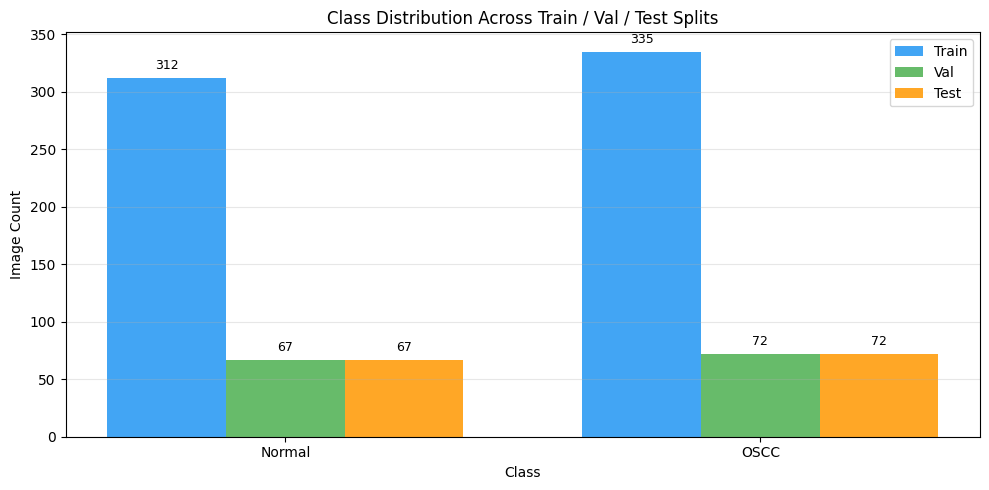

Saved: /content/models/class_distribution.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp'}
split_dir = Path(LOCAL_DATA_SPLIT)
splits = ['train', 'val', 'test']
classes = DETECTED_CLASSES

# Count images per split per class
counts = {}
for sp in splits:
    counts[sp] = {}
    for cls in classes:
        d = split_dir / sp / cls
        n = sum(1 for f in d.iterdir() if f.suffix.lower() in EXTS) if d.exists() else 0
        counts[sp][cls] = n

x = np.arange(len(classes))
width = 0.25
colours = ['#2196F3', '#4CAF50', '#FF9800']

fig, ax = plt.subplots(figsize=(10, 5))
for i, sp in enumerate(splits):
    vals = [counts[sp][c] for c in classes]
    bars = ax.bar(x + i * width, vals, width, label=sp.capitalize(), color=colours[i], alpha=0.85)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
                str(v), ha='center', va='bottom', fontsize=9)

ax.set_xlabel('Class')
ax.set_ylabel('Image Count')
ax.set_title('Class Distribution Across Train / Val / Test Splits')
ax.set_xticks(x + width)
ax.set_xticklabels(classes)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()

plot_path = f'{LOCAL_MODELS}/class_distribution.png'
plt.savefig(plot_path, dpi=150)
plt.show()
import shutil
shutil.copy2(plot_path, DRIVE_MODELS)
print(f'Saved: {plot_path}')

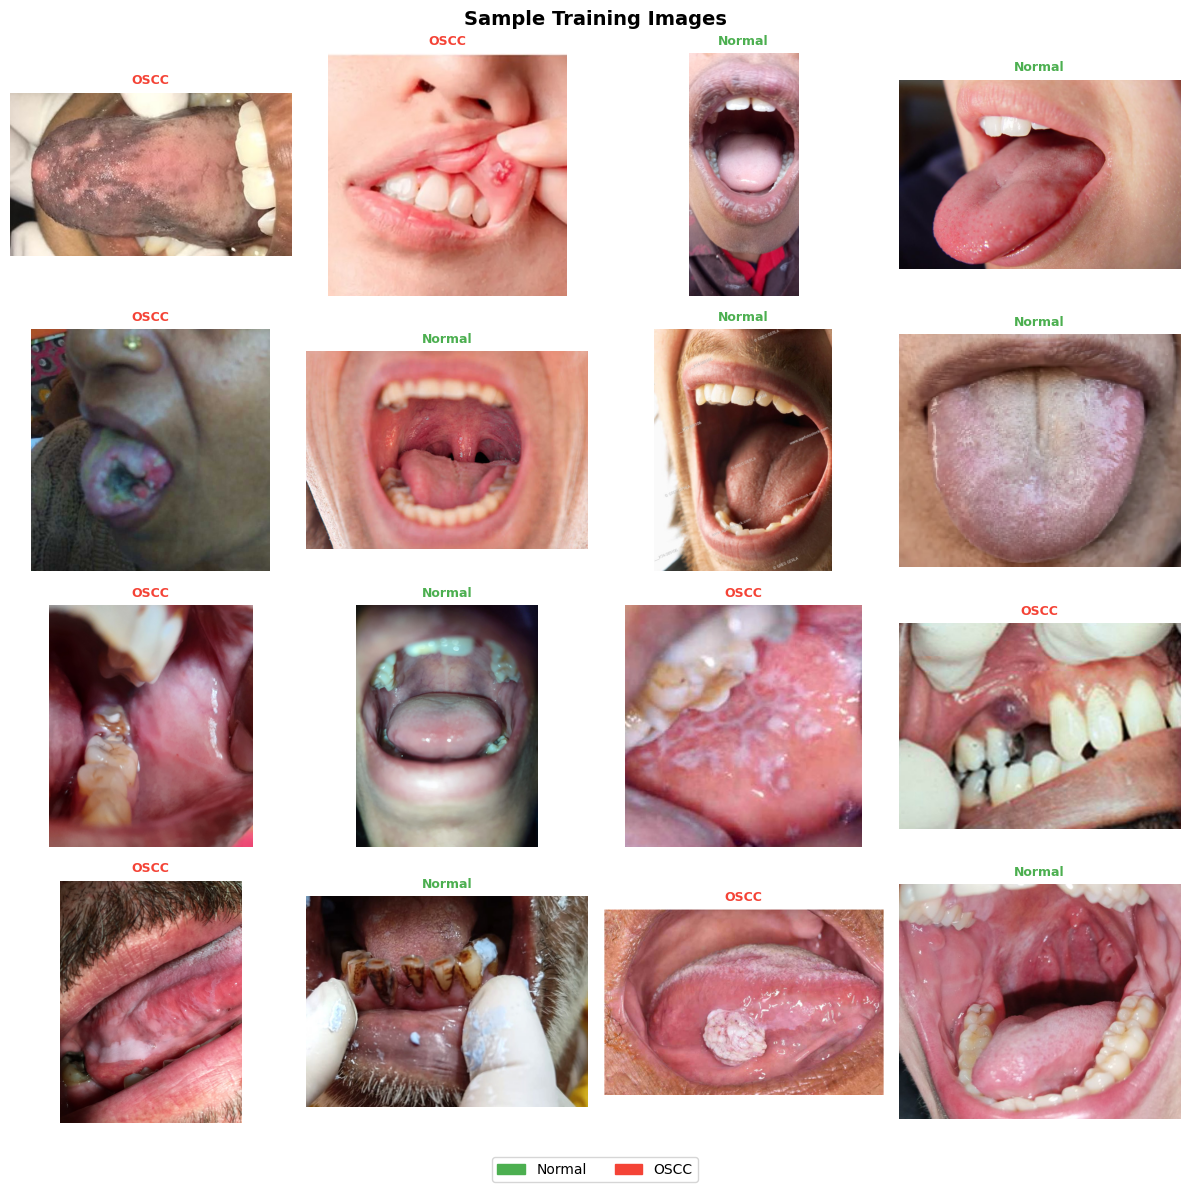

Saved: /content/models/sample_images.png


In [ ]:
import random
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from PIL import Image

EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp'}
split_dir = Path(LOCAL_DATA_SPLIT)
classes = DETECTED_CLASSES
cols = 4
rows = 4
random.seed(42)

# Collect random samples (equal per class)
samples = []
per_class = (cols * rows) // len(classes)
for cls in classes:
    d = split_dir / 'train' / cls
    imgs = [f for f in d.iterdir() if f.suffix.lower() in EXTS] if d.exists() else []
    chosen = random.sample(imgs, min(per_class, len(imgs)))
    samples.extend([(p, cls) for p in chosen])

random.shuffle(samples)
samples = samples[:cols * rows]

# Colour map for class borders
cls_colours = {'Normal': '#4CAF50', 'OSCC': '#F44336'}
default_colour = '#2196F3'

fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
fig.suptitle('Sample Training Images', fontsize=14, fontweight='bold')

for ax, (img_path, cls) in zip(axes.flat, samples):
    img = Image.open(img_path).convert('RGB')
    ax.imshow(img)
    colour = cls_colours.get(cls, default_colour)
    for spine in ax.spines.values():
        spine.set_edgecolor(colour)
        spine.set_linewidth(3)
    ax.set_title(cls, fontsize=9, color=colour, fontweight='bold')
    ax.axis('off')

# Hide unused axes
for ax in axes.flat[len(samples):]:
    ax.axis('off')

# Legend
patches = [mpatches.Patch(color=cls_colours.get(c, default_colour), label=c) for c in classes]
fig.legend(handles=patches, loc='lower center', ncol=len(classes), fontsize=10)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plot_path = f'{LOCAL_MODELS}/sample_images.png'
plt.savefig(plot_path, dpi=150)
plt.show()
import shutil
shutil.copy2(plot_path, DRIVE_MODELS)
print(f'Saved: {plot_path}')

In [ ]:
import os

CONFIG = {
    # Paths
    'data_dir':            LOCAL_DATA_SPLIT,
    'output_dir':          LOCAL_MODELS,
    'drive_dir':           DRIVE_MODELS,
    'best_model_path':     os.path.join(LOCAL_MODELS, BEST_MODEL_NAME),
    'resume_ckpt_path':    os.path.join(LOCAL_MODELS, RESUME_CKPT_NAME),
    'drive_resume_path':   os.path.join(DRIVE_MODELS, RESUME_CKPT_NAME),

    # Model
    'model_name':          'efficientnet_b0',

    # Training
    'epochs':              70,    # Total epochs
    'phase1_epochs':       10,    # Frozen backbone epochs
    'phase1_lr':           1e-3,  # LR for phase 1 (classifier head only)
    'lr':                  1e-4,  # LR for phase 2 (full fine-tune)
    'batch_size':          32,    # Reduce to 16 if CUDA out of memory
    'num_workers':         2,
    'weight_decay':        1e-4,
    'focal_gamma':         2.0,   # Focal loss gamma (handles class imbalance)
    'patience':            20,    # Early stopping patience
    'seed':                42,
    'amp':                 True,  # Mixed precision (faster on T4)

    # Classification Threshold (for binary problems like this one)
    'classification_threshold': 0.15,
}

print('Training configuration:')
for k, v in CONFIG.items():
    print(f'  {k:<22} = {v}')

Training configuration:
  data_dir               = /content/data/split
  output_dir             = /content/models
  drive_dir              = /content/drive/MyDrive/oral_cancer_detection/models
  best_model_path        = /content/models/efficientnet_b3_lips_v1.pth
  resume_ckpt_path       = /content/models/lips_resume_checkpoint.pth
  drive_resume_path      = /content/drive/MyDrive/oral_cancer_detection/models/lips_resume_checkpoint.pth
  model_name             = efficientnet_b0
  epochs                 = 70
  phase1_epochs          = 10
  phase1_lr              = 0.001
  lr                     = 0.0001
  batch_size             = 32
  num_workers            = 2
  weight_decay           = 0.0001
  focal_gamma            = 2.0
  patience               = 20
  seed                   = 42
  amp                    = True
  classification_threshold = 0.15


In [ ]:

import logging
import os
from pathlib import Path

import cv2
import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)
IMAGE_SIZE    = 224
IMG_EXTS      = {'.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp'}

def _train_transforms():
    import albumentations as A
    from albumentations.pytorch import ToTensorV2
    return A.Compose([
        A.Resize(IMAGE_SIZE, IMAGE_SIZE, interpolation=cv2.INTER_LANCZOS4),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.2),
        A.RandomRotate90(p=0.3),
        A.Rotate(limit=15, p=0.3),
        A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.3),
        A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=15, val_shift_limit=10, p=0.3),
        A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.3),
        A.GaussNoise(std_range=(0.01, 0.05), p=0.2),
        A.GaussianBlur(blur_limit=(3, 5), p=0.2),
        A.Affine(translate_percent=0.05, scale=(0.9, 1.1), rotate=(-10, 10), p=0.3),
        A.CoarseDropout(num_holes_range=(1, 3), hole_height_range=(10, 15), hole_width_range=(10, 15), p=0.15),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])

def _val_transforms():
    import albumentations as A
    from albumentations.pytorch import ToTensorV2
    return A.Compose([
        A.Resize(IMAGE_SIZE, IMAGE_SIZE, interpolation=cv2.INTER_LANCZOS4),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])


class OralDataset(Dataset):
    def __init__(self, root_dir, transform=None, class_names=None):
        self.root = Path(root_dir)
        self.transform = transform
        self.class_names = class_names or sorted(
            d.name for d in self.root.iterdir() if d.is_dir()
        )
        self.class_to_idx = {c: i for i, c in enumerate(self.class_names)}
        self.samples, self.labels = [], []
        for cls in self.class_names:
            cls_dir = self.root / cls
            if not cls_dir.exists():
                continue
            for p in sorted(cls_dir.iterdir()):
                if p.suffix.lower() in IMG_EXTS:
                    self.samples.append(str(p))
                    self.labels.append(self.class_to_idx[cls])

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        label = self.labels[idx]
        try:
            img = cv2.imread(self.samples[idx])
            if img is not None:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            else:
                img = np.array(Image.open(self.samples[idx]).convert('RGB'))
        except Exception:
            img = np.zeros((IMAGE_SIZE, IMAGE_SIZE, 3), dtype=np.uint8)
        if self.transform:
            img = self.transform(image=img)['image']
        else:
            img = torch.from_numpy(img.transpose(2, 0, 1)).float() / 255.0
        return img, label


# Build loaders
split_dir = Path(CONFIG['data_dir'])
class_names = DETECTED_CLASSES

train_ds = OralDataset(split_dir / 'train', transform=_train_transforms(), class_names=class_names)
val_ds   = OralDataset(split_dir / 'val',   transform=_val_transforms(),   class_names=class_names)
test_ds  = OralDataset(split_dir / 'test',  transform=_val_transforms(),   class_names=class_names)

kw = dict(num_workers=CONFIG['num_workers'], pin_memory=True)
train_loader = DataLoader(train_ds, batch_size=CONFIG['batch_size'], shuffle=True, **kw)
val_loader   = DataLoader(val_ds,   batch_size=CONFIG['batch_size'], shuffle=False, **kw)
test_loader  = DataLoader(test_ds,  batch_size=CONFIG['batch_size'], shuffle=False, **kw)

num_classes = len(class_names)
print(f'Classes ({num_classes}): {class_names}')
print(f'Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}')

Classes (2): ['Normal', 'OSCC']
Train: 647 | Val: 139 | Test: 139


In [ ]:
#In case we want to delete the existing checkpoint

import os

# Delete the resume checkpoint from Drive
drive_resume = os.path.join(CONFIG['drive_dir'], 'lips_resume_checkpoint.pth')
if os.path.exists(drive_resume):
    os.remove(drive_resume)
    print(f"Deleted: {drive_resume}")

# Also delete the old best model (trained with wrong loss)
old_best = os.path.join(CONFIG['drive_dir'], 'efficientnet_b3_lips_v1.pth')
if os.path.exists(old_best):
    os.remove(old_best)
    print(f"Deleted: {old_best}")

# Delete local copies too
for path in [CONFIG['resume_ckpt_path'], CONFIG['best_model_path']]:
    if os.path.exists(path):
        os.remove(path)
        print(f"Deleted: {path}")

print("\nClean slate. Re-run training cell now.")

Deleted: /content/drive/MyDrive/oral_cancer_detection/models/lips_resume_checkpoint.pth
Deleted: /content/drive/MyDrive/oral_cancer_detection/models/efficientnet_b3_lips_v1.pth

Clean slate. Re-run training cell now.


In [ ]:
import sys
import os
import time
import copy
import shutil
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
import timm
from torch.optim.lr_scheduler import CosineAnnealingLR, OneCycleLR
from tqdm.notebook import tqdm


torch.manual_seed(CONFIG['seed'])
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Training device: {device}')

Path(CONFIG['output_dir']).mkdir(parents=True, exist_ok=True)


# ============================================================
# EARLY STOPPING
# ============================================================
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.001):
        self.patience = patience
        self.min_delta = min_delta
        self.best = float('-inf')
        self.counter = 0

    def step(self, metric):
        if metric > self.best + self.min_delta:
            self.best = metric
            self.counter = 0
        else:
            self.counter += 1
        return self.counter >= self.patience


# ============================================================
# CHECKPOINT HELPERS
# ============================================================
def strip_module_prefix(state_dict):
    if not isinstance(state_dict, dict):
        return state_dict
    if all(k.startswith('module.') for k in state_dict.keys()):
        return {k[len('module.'):]: v for k, v in state_dict.items()}
    return state_dict


def extract_model_state_dict(ckpt):
    if ckpt is None or not isinstance(ckpt, dict):
        return None

    for key in ['model_state_dict', 'modelstatedict', 'state_dict', 'statedict', 'model', 'model_weights', 'net']:
        if key in ckpt and isinstance(ckpt[key], dict):
            return strip_module_prefix(ckpt[key])

    tensor_like_values = sum(
        1 for v in ckpt.values()
        if torch.is_tensor(v) or isinstance(v, torch.nn.Parameter)
    )
    if tensor_like_values > 0:
        return strip_module_prefix(ckpt)

    return None


def safe_get(ckpt, key, default=None):
    if not isinstance(ckpt, dict):
        return default
    if key in ckpt:
        return ckpt[key]
    alt_key = key.replace('_', '')
    if alt_key in ckpt:
        return ckpt[alt_key]
    return default


def maybe_load_state_dict(target, state, name):
    if state is None:
        print(f'No {name} found in checkpoint; skipping.')
        return False
    try:
        target.load_state_dict(state)
        print(f'{name} loaded from checkpoint.')
        return True
    except Exception as e:
        print(f'Could not load {name}: {e}')
        return False

# ============================================================
# RESUME DETECTION
# ============================================================
resume_path  = CONFIG['resume_ckpt_path']
drive_resume = CONFIG['drive_resume_path']

if not os.path.exists(resume_path) and os.path.exists(drive_resume):
    print('Restoring resume checkpoint from Drive...')
    shutil.copy2(drive_resume, resume_path)

loaded_ckpt  = None
start_epoch  = 1
start_phase  = 1
best_val_acc = 0.0
history      = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

if os.path.exists(resume_path):
    loaded_ckpt = torch.load(resume_path, map_location=device, weights_only=False)

    if isinstance(loaded_ckpt, dict):
        print('Checkpoint keys:', list(loaded_ckpt.keys())[:20])

    start_epoch  = safe_get(loaded_ckpt, 'epoch', 0) + 1
    start_phase  = safe_get(loaded_ckpt, 'phase', 1)
    best_val_acc = safe_get(loaded_ckpt, 'best_val_acc', 0.0)

    raw_history = safe_get(loaded_ckpt, 'history', None)
    if raw_history and isinstance(raw_history, dict):
        history = {
            'train_loss': raw_history.get('train_loss', raw_history.get('trainloss', [])),
            'val_loss':   raw_history.get('val_loss',   raw_history.get('valloss', [])),
            'train_acc':  raw_history.get('train_acc',  raw_history.get('trainacc', [])),
            'val_acc':    raw_history.get('val_acc',    raw_history.get('valacc', [])),
        }
    else:
        history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    print(
        f'RESUME file found | '
        f'start_epoch={start_epoch} | '
        f'start_phase={start_phase} | '
        f'best_val_acc={best_val_acc:.2f}%'
    )
else:
    print('No resume checkpoint — starting fresh training.')
# ============================================================
# MODEL
# ============================================================
model = timm.create_model(
    CONFIG['model_name'],
    pretrained=(loaded_ckpt is None),
    num_classes=num_classes,
    drop_rate=0.3,
)
model = model.to(device)

loaded_model_weights = False
if loaded_ckpt is not None:
    model_state = extract_model_state_dict(loaded_ckpt)

    if model_state is not None:
        try:
            model.load_state_dict(model_state)
            loaded_model_weights = True
            print('Model weights loaded from checkpoint.')
        except RuntimeError as e:
            print(f'Strict model load failed: {e}')
            print('Retrying with strict=False ...')
            missing, unexpected = model.load_state_dict(model_state, strict=False)
            loaded_model_weights = True
            print(f'Model loaded with strict=False.')
            print(f'Missing keys: {missing}')
            print(f'Unexpected keys: {unexpected}')
    else:
        print('Checkpoint found, but no recognizable model state dict was present.')

if not loaded_model_weights:
    total = sum(p.numel() for p in model.parameters())
    print(f'{CONFIG["model_name"]} built. Params: {total:,}')


criterion = nn.CrossEntropyLoss()
scaler = torch.amp.GradScaler('cuda') if (CONFIG['amp'] and device.type == 'cuda') else None


# ============================================================
# TRAINING HELPERS
# ============================================================
def train_epoch(loader, optimizer, scheduler=None):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    pbar = tqdm(loader, desc='Train', leave=False)

    for inputs, labels in pbar:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)

        if scaler:
            with torch.amp.autocast('cuda'):
                out  = model(inputs)
                loss = criterion(out, labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            out  = model(inputs)
            loss = criterion(out, labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        if scheduler is not None:
            scheduler.step()

        total_loss += loss.item() * inputs.size(0)
        correct += (out.argmax(1) == labels).sum().item()
        total += inputs.size(0)
        pbar.set_postfix(loss=f'{loss.item():.3f}', acc=f'{correct / total * 100:.1f}%')

    return total_loss / total, correct / total * 100


@torch.no_grad()
def eval_epoch(loader, desc='Val'):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for inputs, labels in tqdm(loader, desc=desc, leave=False):
        inputs, labels = inputs.to(device), labels.to(device)
        out = model(inputs)
        loss = criterion(out, labels)
        total_loss += loss.item() * inputs.size(0)
        correct += (out.argmax(1) == labels).sum().item()
        total += inputs.size(0)

    return total_loss / total, correct / total * 100


def save_best_model(epoch, val_acc):
    path = CONFIG['best_model_path']
    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'val_acc': val_acc,
        'class_names': class_names,
        'num_classes': num_classes,
        'model_name': CONFIG['model_name'],
        'pytorch_version': torch.__version__,
    }, path)
    shutil.copy2(path, os.path.join(CONFIG['drive_dir'], BEST_MODEL_NAME))


def save_resume_checkpoint(epoch, phase, optimizer, scheduler):
    path = CONFIG['resume_ckpt_path']
    torch.save({
        'epoch': epoch,
        'phase': phase,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict() if optimizer is not None else None,
        'scheduler_state_dict': scheduler.state_dict() if scheduler is not None else None,
        'scaler_state_dict': scaler.state_dict() if scaler else None,
        'best_val_acc': best_val_acc,
        'history': history,
        'class_names': class_names,
        'num_classes': num_classes,
        'model_name': CONFIG['model_name'],
        'config': CONFIG,
        'pytorch_version': torch.__version__,
    }, path)
    shutil.copy2(path, CONFIG['drive_resume_path'])


def log_epoch(tag, epoch, tl, ta, vl, va, elapsed, is_best):
    star = '  ★ BEST' if is_best else ''
    print(
        f'[{tag}] Epoch {epoch:3d}/{CONFIG["epochs"]} | '
        f'Train loss={tl:.4f} acc={ta:.1f}% | '
        f'Val loss={vl:.4f} acc={va:.1f}% | '
        f'{elapsed:.0f}s{star}'
    )


# ============================================================
# PHASE 1 — Frozen backbone (CosineAnnealingLR: epoch-based)
# ============================================================
if start_phase == 1:
    print(f'\n=== PHASE 1: Classifier head training (epochs 1–{CONFIG["phase1_epochs"]}) ===')

    for name, param in model.named_parameters():
        if 'classifier' not in name and 'head' not in name:
            param.requires_grad = False

    optimizer_p1 = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=CONFIG['phase1_lr'],
        weight_decay=CONFIG['weight_decay'],
    )
    scheduler_p1 = CosineAnnealingLR(optimizer_p1, T_max=CONFIG['phase1_epochs'])

    if isinstance(loaded_ckpt, dict) and safe_get(loaded_ckpt, 'phase', None) == 1:
        maybe_load_state_dict(
            optimizer_p1,
            safe_get(loaded_ckpt, 'optimizer_state_dict', None),
            'optimizer state'
        )
        maybe_load_state_dict(
            scheduler_p1,
            safe_get(loaded_ckpt, 'scheduler_state_dict', None),
            'scheduler state'
        )
        if scaler is not None:
            maybe_load_state_dict(
                scaler,
                safe_get(loaded_ckpt, 'scaler_state_dict', None),
                'scaler state'
            )

    phase1_end = min(CONFIG['phase1_epochs'], CONFIG['epochs'])

    for epoch in range(start_epoch, phase1_end + 1):
        t0 = time.time()
        tl, ta = train_epoch(train_loader, optimizer_p1)
        vl, va = eval_epoch(val_loader)
        scheduler_p1.step()

        history['train_loss'].append(tl)
        history['val_loss'].append(vl)
        history['train_acc'].append(ta)
        history['val_acc'].append(va)

        is_best = va > best_val_acc
        if is_best:
            best_val_acc = va
            save_best_model(epoch, va)

        log_epoch('P1', epoch, tl, ta, vl, va, time.time() - t0, is_best)
        save_resume_checkpoint(epoch, 1, optimizer_p1, scheduler_p1)

    start_epoch = CONFIG['phase1_epochs'] + 1
else:
    print('=== PHASE 1: Already completed. Skipping. ===')


# ============================================================
# PHASE 2 — Full fine-tuning (OneCycleLR: per-batch)
# ============================================================
remaining_epochs = CONFIG['epochs'] - CONFIG['phase1_epochs']

if remaining_epochs > 0:
    p2_start = start_epoch if start_phase == 2 else CONFIG['phase1_epochs'] + 1
    print(f'\n=== PHASE 2: Full fine-tuning (epochs {p2_start}–{CONFIG["epochs"]}) ===')

    for param in model.parameters():
        param.requires_grad = True

    optimizer_p2 = optim.AdamW(
        model.parameters(),
        lr=4e-5,
        weight_decay=CONFIG['weight_decay'],
    )

    scheduler_p2 = OneCycleLR(
        optimizer_p2,
        max_lr=4e-5,
        steps_per_epoch=len(train_loader),
        epochs=remaining_epochs,
        pct_start=0.1,
        last_epoch=-1,
    )

    if isinstance(loaded_ckpt, dict) and safe_get(loaded_ckpt, 'phase', None) == 2:
        maybe_load_state_dict(
            optimizer_p2,
            safe_get(loaded_ckpt, 'optimizer_state_dict', None),
            'optimizer state'
        )
        maybe_load_state_dict(
            scheduler_p2,
            safe_get(loaded_ckpt, 'scheduler_state_dict', None),
            'scheduler state'
        )
        if scaler is not None:
            maybe_load_state_dict(
                scaler,
                safe_get(loaded_ckpt, 'scaler_state_dict', None),
                'scaler state'
            )

    early_stop = EarlyStopping(patience=CONFIG['patience'])

    for epoch in range(p2_start, CONFIG['epochs'] + 1):
        t0 = time.time()
        tl, ta = train_epoch(train_loader, optimizer_p2, scheduler=scheduler_p2)
        vl, va = eval_epoch(val_loader)

        history['train_loss'].append(tl)
        history['val_loss'].append(vl)
        history['train_acc'].append(ta)
        history['val_acc'].append(va)

        is_best = va > best_val_acc
        if is_best:
            best_val_acc = va
            save_best_model(epoch, va)

        log_epoch('P2', epoch, tl, ta, vl, va, time.time() - t0, is_best)
        save_resume_checkpoint(epoch, 2, optimizer_p2, scheduler_p2)

        if early_stop.step(va):
            print(f'Early stopping triggered at epoch {epoch}.')
            break

print(f'\nTraining complete. Best validation accuracy: {best_val_acc:.2f}%')
print(f'Best model: {CONFIG["best_model_path"]}')
print(f'Drive copy: {os.path.join(CONFIG["drive_dir"], BEST_MODEL_NAME)}')

Training device: cuda
No resume checkpoint — starting fresh training.


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

efficientnet_b0 built. Params: 4,010,110

=== PHASE 1: Classifier head training (epochs 1–10) ===


Train:   0%|          | 0/21 [00:00<?, ?it/s]

...

Val:   0%|          | 0/5 [00:00<?, ?it/s]

[P2] Epoch  56/70 | Train loss=0.0614 acc=98.8% | Val loss=0.4787 acc=94.2% | 16s


Train:   0%|          | 0/21 [00:00<?, ?it/s]

Val:   0%|          | 0/5 [00:00<?, ?it/s]

[P2] Epoch  57/70 | Train loss=0.1670 acc=96.6% | Val loss=0.4662 acc=93.5% | 15s
Early stopping triggered at epoch 57.

Training complete. Best validation accuracy: 96.40%
Best model: /content/models/efficientnet_b3_lips_v1.pth
Drive copy: /content/drive/MyDrive/oral_cancer_detection/models/efficientnet_b3_lips_v1.pth


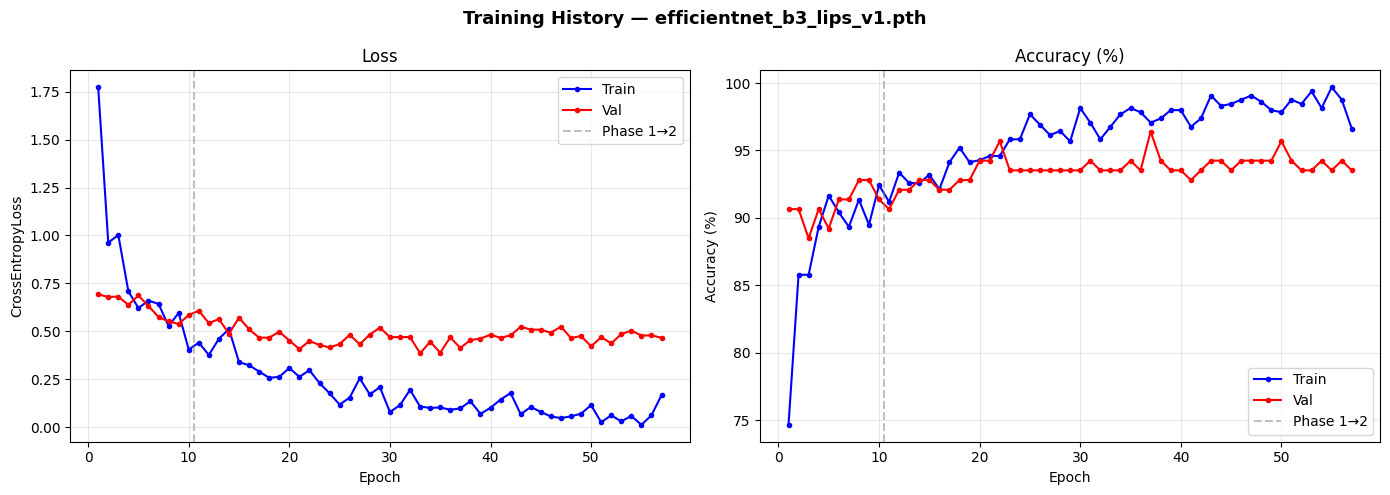

Best val accuracy: 96.40%
Total epochs trained: 57
Saved to Drive: training_history.png, training_history.csv


In [ ]:
import csv
import shutil
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path(CONFIG['output_dir'])

if not history['train_loss']:
    print('No training history available. Run Cell 11 first.')
else:
    epochs_range = range(1, len(history['train_loss']) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f'Training History — {BEST_MODEL_NAME}', fontsize=13, fontweight='bold')

    # Loss panel
    axes[0].plot(epochs_range, history['train_loss'], 'b-o', label='Train', markersize=3)
    axes[0].plot(epochs_range, history['val_loss'],   'r-o', label='Val',   markersize=3)
    axes[0].set_title('Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('CrossEntropyLoss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Accuracy panel
    axes[1].plot(epochs_range, history['train_acc'], 'b-o', label='Train', markersize=3)
    axes[1].plot(epochs_range, history['val_acc'],   'r-o', label='Val',   markersize=3)
    axes[1].set_title('Accuracy (%)')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy (%)')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    # Phase 1 / Phase 2 boundary line
    p1_end = CONFIG['phase1_epochs']
    if p1_end < len(history['train_loss']):
        for ax in axes:
            ax.axvline(x=p1_end + 0.5, color='gray', linestyle='--', alpha=0.5, label='Phase 1→2')
            ax.legend()

    plt.tight_layout()
    plot_path = str(output_dir / 'training_history.png')
    plt.savefig(plot_path, dpi=150, bbox_inches='tight')
    plt.show()

    # CSV
    csv_path = str(output_dir / 'training_history.csv')
    with open(csv_path, 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['epoch', 'train_loss', 'val_loss', 'train_acc', 'val_acc'])
        writer.writeheader()
        for i in range(len(history['train_loss'])):
            writer.writerow({
                'epoch':      i + 1,
                'train_loss': history['train_loss'][i],
                'val_loss':   history['val_loss'][i],
                'train_acc':  history['train_acc'][i],
                'val_acc':    history['val_acc'][i],
            })

    for fname in ['training_history.png', 'training_history.csv']:
        src = output_dir / fname
        if src.exists():
            shutil.copy2(str(src), CONFIG['drive_dir'])
    print(f'Best val accuracy: {best_val_acc:.2f}%')
    print(f'Total epochs trained: {len(history["train_loss"])}')
    print(f'Saved to Drive: training_history.png, training_history.csv')

Loaded best model (epoch 37, val_acc=96.40%)


Testing:   0%|          | 0/5 [00:00<?, ?it/s]

Using classification threshold: 0.15

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

      Normal     0.9143    0.9552    0.9343        67
        OSCC     0.9565    0.9167    0.9362        72

    accuracy                         0.9353       139
   macro avg     0.9354    0.9359    0.9352       139
weighted avg     0.9362    0.9353    0.9353       139



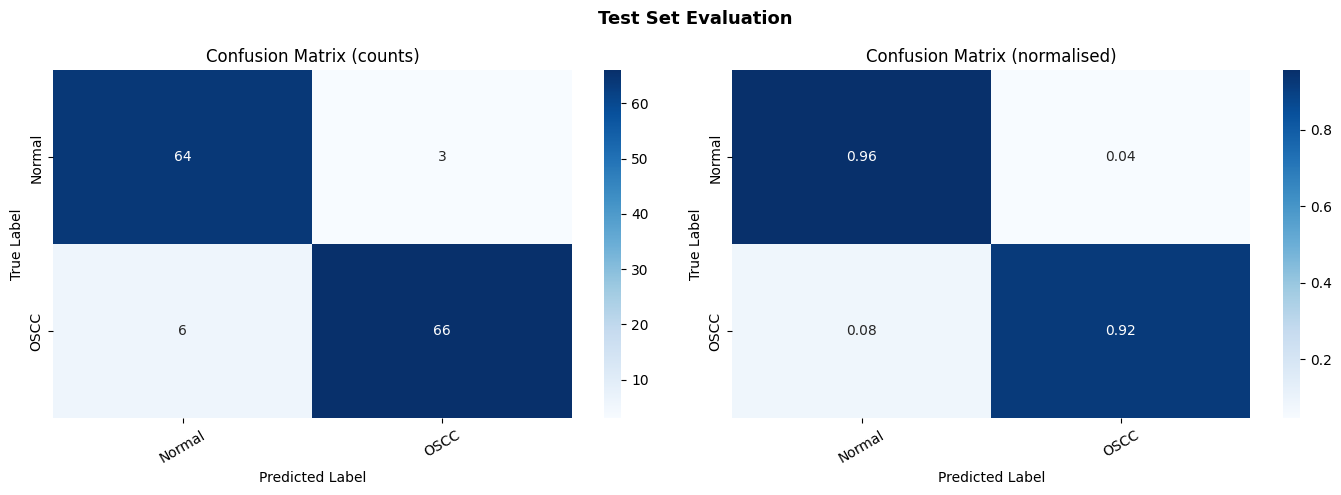

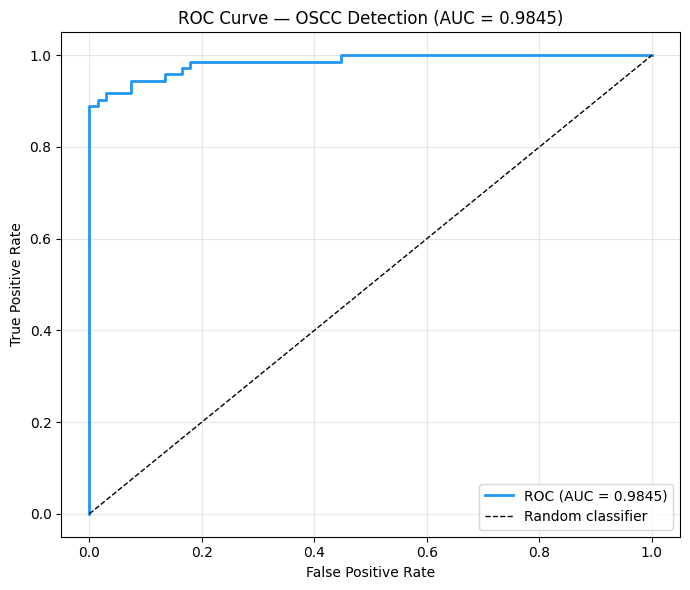

ROC AUC: 0.9845
Evaluation plots saved to Drive.

=== THRESHOLD SWEEP ===
Thresh   Acc      Precision   Recall   F1      
0.50     0.935    0.970       0.903    0.935   
0.45     0.935    0.970       0.903    0.935   
0.40     0.935    0.970       0.903    0.935   
0.35     0.942    0.971       0.917    0.943   
0.30     0.942    0.971       0.917    0.943   
0.25     0.942    0.971       0.917    0.943   
0.20     0.935    0.957       0.917    0.936   
0.15     0.935    0.957       0.917    0.936   
0.10     0.928    0.943       0.917    0.930   
0.05     0.928    0.943       0.917    0.930   
0.03     0.928    0.931       0.931    0.931   


In [ ]:
import shutil
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm.notebook import tqdm
from sklearn.metrics import(
    classification_report, confusion_matrix,
    roc_curve, auc,
)
import os # Added for os.path operations

output_dir = Path(CONFIG['output_dir'])

# Restore best model from Drive if missing locally
best_path  = CONFIG['best_model_path']
drive_best = os.path.join(CONFIG['drive_dir'], BEST_MODEL_NAME)

if not os.path.exists(best_path):
    if os.path.exists(drive_best):
        shutil.copy2(drive_best, best_path)
        print('Model restored from Drive.')
    else:
        raise FileNotFoundError('Trained model not found. Run Cell 11 first.')

# Load best model
best_ckpt = torch.load(CONFIG['best_model_path'], map_location=device, weights_only=False)
model.load_state_dict(best_ckpt['model_state_dict'])
model.eval()
print(f'Loaded best model (epoch {best_ckpt["epoch"]}, val_acc={best_ckpt["val_acc"]:.2f}%)')

# Collect predictions and probabilities
all_preds, all_labels, all_probs = [], [], []
with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc='Testing'):
        outputs = model(inputs.to(device))
        probs = torch.softmax(outputs, dim=1).cpu().numpy()
        all_probs.extend(probs)
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(labels.numpy())

all_probs  = np.array(all_probs)
all_labels = np.array(all_labels)

# Apply custom classification threshold if num_classes == 2
if num_classes == 2 and 'classification_threshold' in CONFIG:
    oscc_idx = class_names.index('OSCC') if 'OSCC' in class_names else 1
    # For binary classification, we care about the probability of the positive class (OSCC)
    oscc_probs = all_probs[:, oscc_idx]
    # If P(OSCC) >= threshold, predict OSCC (oscc_idx), else predict Normal (the other class index)
    all_preds_thresholded = np.where(oscc_probs >= CONFIG['classification_threshold'], oscc_idx, 1 - oscc_idx)
    all_preds = all_preds_thresholded
    print(f"Using classification threshold: {CONFIG['classification_threshold']:.2f}")
else:
    all_preds = np.array(all_preds)
    print("Using argmax for predictions (no custom threshold applied).")

# ---- Classification Report ----
print('\n=== CLASSIFICATION REPORT ===')
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

# ---- Confusion Matrix ----
cm = confusion_matrix(all_labels, all_preds)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Test Set Evaluation', fontsize=13, fontweight='bold')

# Raw counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Confusion Matrix (counts)')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')
axes[0].tick_params(axis='x', rotation=30)

# Normalised
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Confusion Matrix (normalised)')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
cm_path = str(output_dir / 'confusion_matrix.png')
plt.savefig(cm_path, dpi=150, bbox_inches='tight')
plt.show()
shutil.copy2(cm_path, CONFIG['drive_dir'])

# ---- ROC Curve (binary: OSCC vs Normal) ----
if num_classes == 2:
    oscc_idx = class_names.index('OSCC') if 'OSCC' in class_names else 1
    y_score  = all_probs[:, oscc_idx]
    y_true_binary = (all_labels == oscc_idx).astype(int)
    fpr, tpr, _ = roc_curve(y_true_binary, y_score)
    roc_auc = auc(fpr, tpr)

    fig, ax = plt.subplots(figsize=(7, 6))
    ax.plot(fpr, tpr, color='#2196F3', lw=2, label=f'ROC (AUC = {roc_auc:.4f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random classifier')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'ROC Curve — OSCC Detection (AUC = {roc_auc:.4f})')
    ax.legend(loc='lower right')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    roc_path = str(output_dir / 'roc_curve.png')
    plt.savefig(roc_path, dpi=150)
    plt.show()
    shutil.copy2(roc_path, CONFIG['drive_dir'])
    print(f'ROC AUC: {roc_auc:.4f}')

print('Evaluation plots saved to Drive.')

# Threshold sweep for recall optimization
if num_classes == 2:
    from sklearn.metrics import recall_score, precision_score, accuracy_score
    print('\n=== THRESHOLD SWEEP ===')
    print(f'{"Thresh":<8} {"Acc":<8} {"Precision":<11} {"Recall":<8} {"F1":<8}')
    oscc_probs = all_probs[:, oscc_idx]
    y_true = (all_labels == oscc_idx).astype(int)
    for t in [0.5, 0.45, 0.4, 0.35, 0.3, 0.25, 0.2, 0.15, 0.10, 0.05, 0.03]:
        preds = (oscc_probs >= t).astype(int)
        acc = accuracy_score(y_true, preds)
        prec = precision_score(y_true, preds)
        rec = recall_score(y_true, preds)
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0
        print(f'{t:<8.2f} {acc:<8.3f} {prec:<11.3f} {rec:<8.3f} {f1:<8.3f}')

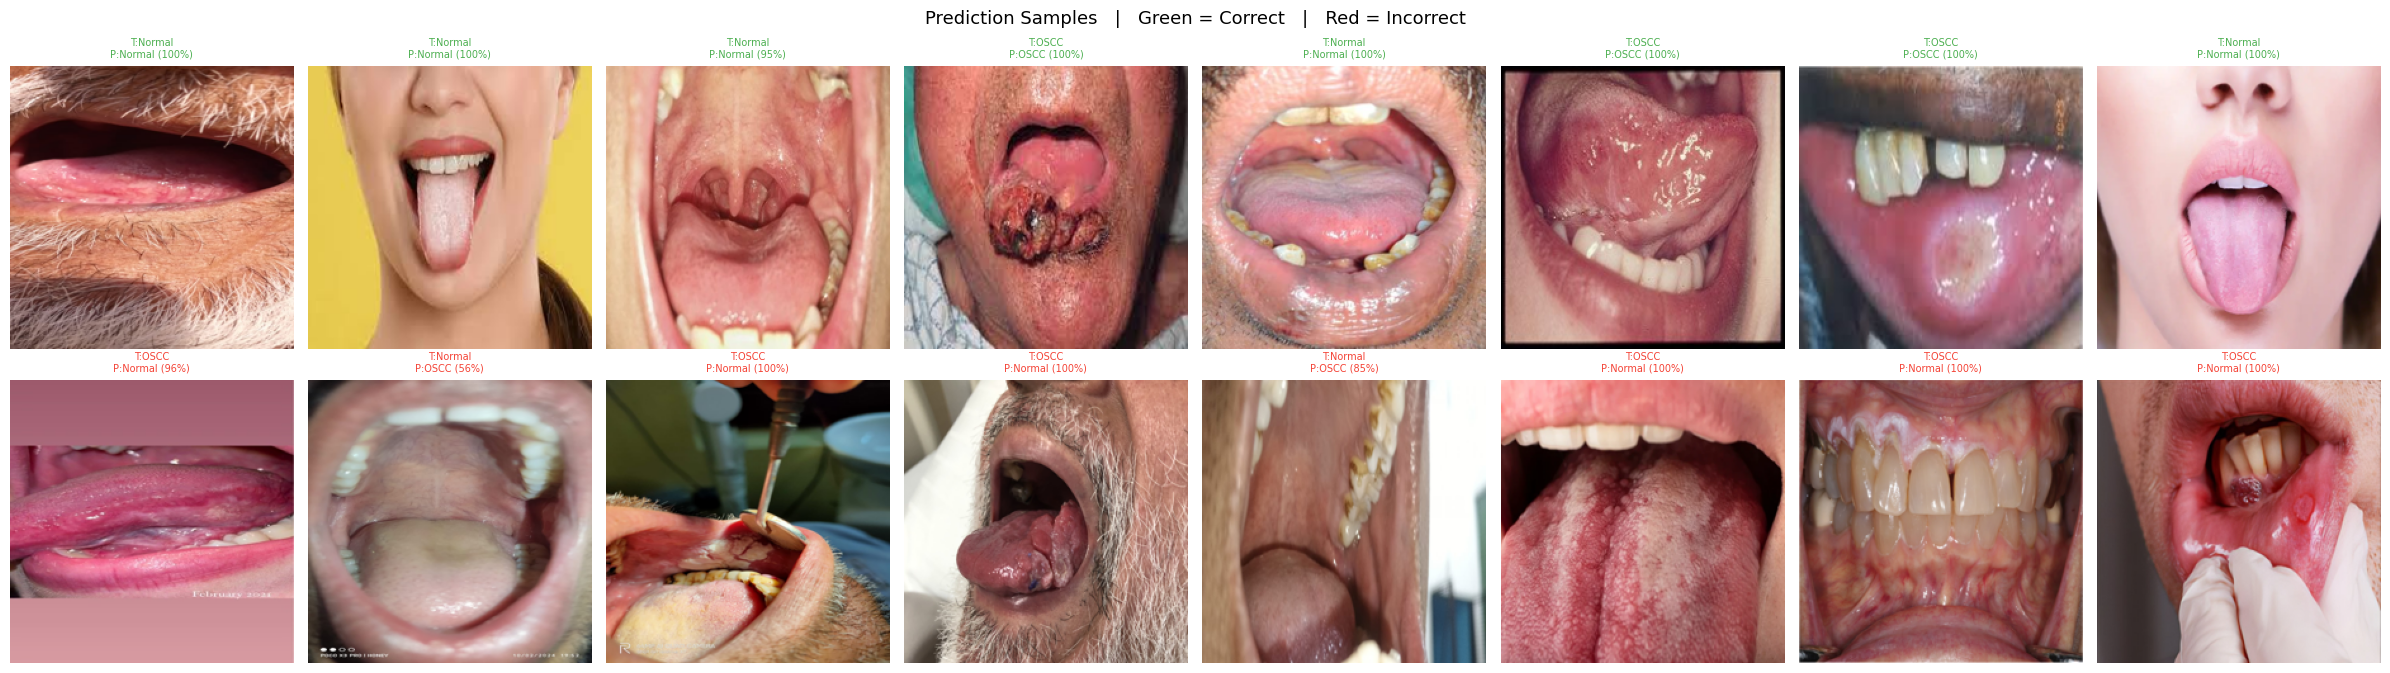

Correct shown: 8 | Incorrect shown: 8
Saved: /content/models/prediction_samples.png


In [ ]:
import random
import shutil
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

output_dir = Path(CONFIG['output_dir'])
split_dir  = Path(CONFIG['data_dir'])
IMG_EXTS   = {'.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp'}

# Collect all test image paths with true labels
test_samples = []  # (path, true_label_idx)
for cls_idx, cls in enumerate(class_names):
    d = split_dir / 'test' / cls
    if d.exists():
        for p in d.iterdir():
            if p.suffix.lower() in IMG_EXTS:
                test_samples.append((p, cls_idx))

random.seed(99)
random.shuffle(test_samples)

# Run inference on a batch
model.eval()
correct_samples = []
wrong_samples   = []

import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2

infer_tf = A.Compose([
    A.Resize(224, 224, interpolation=cv2.INTER_LANCZOS4),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

for img_path, true_idx in test_samples:
    if len(correct_samples) >= 8 and len(wrong_samples) >= 8:
        break
    try:
        img_np = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
        tensor = infer_tf(image=img_np)['image'].unsqueeze(0).to(device)
        with torch.no_grad():
            logits = model(tensor)
            probs  = torch.softmax(logits, dim=1).squeeze(0).cpu().numpy()
        pred_idx = int(probs.argmax())
        conf     = float(probs[pred_idx])
        entry    = (img_path, true_idx, pred_idx, conf)
        if pred_idx == true_idx and len(correct_samples) < 8:
            correct_samples.append(entry)
        elif pred_idx != true_idx and len(wrong_samples) < 8:
            wrong_samples.append(entry)
    except Exception:
        continue

# Display: 2 rows — top 8 correct, bottom 8 wrong
all_display = correct_samples[:8] + wrong_samples[:8]
fig, axes = plt.subplots(2, 8, figsize=(24, 7))
fig.suptitle('Prediction Samples   |   Green = Correct   |   Red = Incorrect', fontsize=13)

for idx, (img_path, true_idx, pred_idx, conf) in enumerate(all_display):
    ax = axes[idx // 8][idx % 8]
    img = Image.open(img_path).convert('RGB').resize((224, 224))
    ax.imshow(img)
    correct = (pred_idx == true_idx)
    border_col = '#4CAF50' if correct else '#F44336'
    for spine in ax.spines.values():
        spine.set_edgecolor(border_col)
        spine.set_linewidth(4)
    true_name = class_names[true_idx]
    pred_name = class_names[pred_idx]
    ax.set_title(f'T:{true_name}\nP:{pred_name} ({conf*100:.0f}%)',
                 fontsize=7, color=border_col)
    ax.axis('off')

# Hide unused
for idx in range(len(all_display), 16):
    axes[idx // 8][idx % 8].axis('off')

plt.tight_layout()
pred_path = str(output_dir / 'prediction_samples.png')
plt.savefig(pred_path, dpi=150, bbox_inches='tight')
plt.show()
shutil.copy2(pred_path, CONFIG['drive_dir'])
print(f'Correct shown: {len(correct_samples)} | Incorrect shown: {len(wrong_samples)}')
print(f'Saved: {pred_path}')

In [ ]:
import os
import shutil
from google.colab import files

best_path  = CONFIG['best_model_path']
drive_best = os.path.join(CONFIG['drive_dir'], BEST_MODEL_NAME)

# Restore from Drive if missing locally (e.g. after Colab reconnect)
if not os.path.exists(best_path):
    if os.path.exists(drive_best):
        shutil.copy2(drive_best, best_path)
        print('Model restored from Drive.')
    else:
        raise FileNotFoundError('Trained model not found. Run Cell 11 first.')

size_mb = os.path.getsize(best_path) / 1e6

# Verify checkpoint integrity before downloading
ckpt = torch.load(best_path, map_location='cpu', weights_only=False)
print('=== Checkpoint Info ===')
print(f'  Model name   : {ckpt.get("model_name", "efficientnet_b3")}')
print(f'  Best epoch   : {ckpt.get("epoch")}')
print(f'  Val accuracy : {ckpt.get("val_acc", 0):.2f}%')
print(f'  Classes ({ckpt.get("num_classes")}): {ckpt.get("class_names")}')
print(f'  File size    : {size_mb:.1f} MB')
print()
print(f'Downloading: {BEST_MODEL_NAME}')
files.download(best_path)
print()
print('After download, move the file to:')
print('  D:\\oral_cancer_detection\\models\\efficientnet_b3_lips_v1.pth')
print()
print('Then update MODEL_PATH in .env:')
print('  # MODEL_PATH=models/efficientnet_b3_lips_v1.pth  (uncomment this line)')
print('And restart the backend: python backend/app.py')

=== Checkpoint Info ===
  Model name   : efficientnet_b0
  Best epoch   : 37
  Val accuracy : 96.40%
  Classes (2): ['Normal', 'OSCC']
  File size    : 16.3 MB

Downloading: efficientnet_b3_lips_v1.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


After download, move the file to:
  D:\oral_cancer_detection\models\efficientnet_b3_lips_v1.pth

Then update MODEL_PATH in .env:
  # MODEL_PATH=models/efficientnet_b3_lips_v1.pth  (uncomment this line)
And restart the backend: python backend/app.py


In [ ]:
# import os
# import shutil
# from pathlib import Path

# print('===============================')
# print('       CLEANUP UTILITY        ')
# print('===============================')
# print()
# print('This will permanently delete:')
# print('  [A] Dataset from Colab  (/content/data/)')
# print('  [B] Dataset zip/folder from Drive')
# print('  [C] Trained model from Colab  (after you confirm download)')
# print('  [D] Trained model from Drive  (after you confirm download)')
# print()
# print('Plots, history CSV, and resume checkpoint are KEPT on Drive.')
# print()

# # ---- Step A: Delete local dataset ----
# deleted = []
# for local_path in [LOCAL_DATA_RAW, LOCAL_DATA_SPLIT]:
#     if os.path.exists(local_path):
#         shutil.rmtree(local_path)
#         deleted.append(local_path)

# if deleted:
#     print(f'[A] Deleted local dataset directories: {deleted}')
# else:
#     print('[A] Local dataset already gone.')

# # ---- Step B: Delete dataset from Drive ----
# drive_items_deleted = []
# for drive_path in [
#     f'{DRIVE_DATA}/kaggle_lips.zip',
#     f'{DRIVE_DATA}/kaggle_lips',
#     f'{DRIVE_DATA}/split',
#     f'{DRIVE_DATA}/raw',
# ]:
#     if os.path.isfile(drive_path):
#         os.remove(drive_path)
#         drive_items_deleted.append(drive_path)
#     elif os.path.isdir(drive_path):
#         shutil.rmtree(drive_path)
#         drive_items_deleted.append(drive_path)

# if drive_items_deleted:
#     print(f'[B] Deleted Drive dataset items:')
#     for item in drive_items_deleted:
#         print(f'    {item}')
# else:
#     print('[B] No Drive dataset items found.')

# print()

# # ---- Step C+D: Delete model weights (guarded) ----
# best_local = CONFIG['best_model_path']
# best_drive = os.path.join(CONFIG['drive_dir'], BEST_MODEL_NAME)

# print('Before deleting model weights, confirm you have successfully moved')
# print(f'  {BEST_MODEL_NAME}')
# print('to your local folder:')
# print('  D:\\oral_cancer_detection\\models\\')
# print()
# confirm = input('Type YES to delete model weights from Colab + Drive: ').strip().upper()

# if confirm == 'YES':
#     if os.path.exists(best_local):
#         os.remove(best_local)
#         print(f'[C] Deleted local model: {best_local}')
#     else:
#         print('[C] Local model already gone.')

#     if os.path.exists(best_drive):
#         os.remove(best_drive)
#         print(f'[D] Deleted Drive model: {best_drive}')
#     else:
#         print('[D] Drive model already gone.')

#     print()
#     print('Cleanup complete.')
#     print('Retained on Drive (small files):')
#     print(f'  {DRIVE_MODELS}/training_history.png')
#     print(f'  {DRIVE_MODELS}/training_history.csv')
#     print(f'  {DRIVE_MODELS}/confusion_matrix.png')
#     print(f'  {DRIVE_MODELS}/roc_curve.png')
#     print(f'  {DRIVE_MODELS}/prediction_samples.png')
#     print(f'  {DRIVE_MODELS}/{RESUME_CKPT_NAME}')
# else:
#     print('Model deletion cancelled — weights retained.')